# MISO: Win Probability from Multiple Early-Game Stats

A single stat like CS only tells part of the story. For this notebook we will consider 3 inputs, CS@10, gold difference@10 and if first blood was secured by the time ( they get the first kill in the match which gives more gold)

This is a multiple-input, single-output network: it takes a weighted sum across all three stats instead of scaling just one
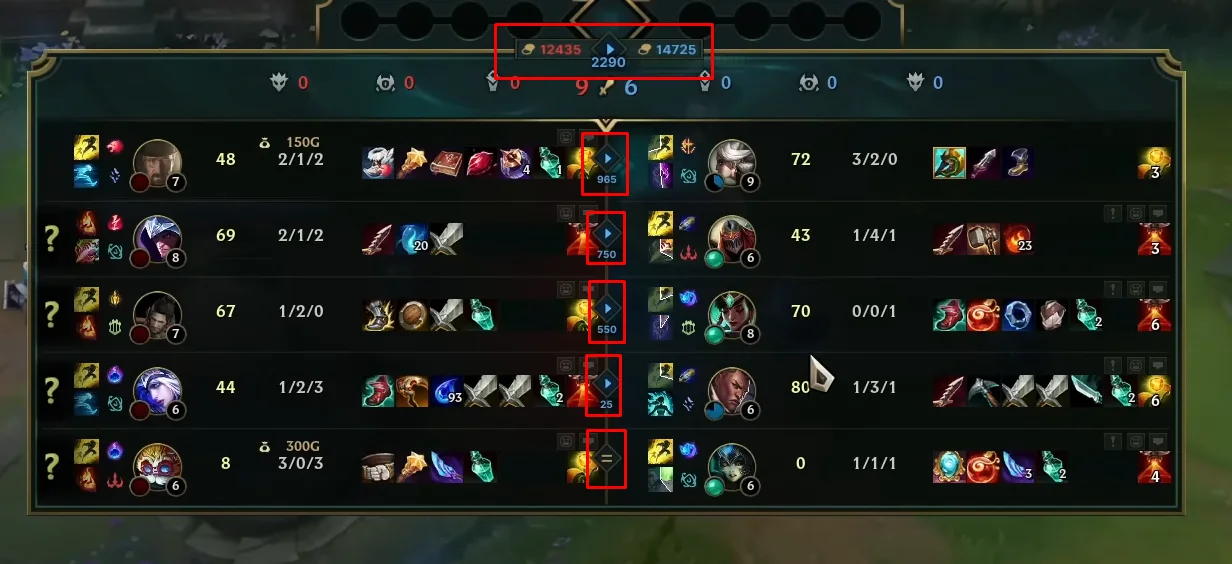

In [1]:
def w_sum(a, b):
    assert(len(a) == len(b))
    output = 0
    for i in range(len(a)):
        output += (a[i] * b[i])
    return output

weights = [0.005, 0.0003, 0.15]

def neural_network(input, weights):
    pred = w_sum(input, weights)
    return pred

# 4 sample games
cs_at_10     = [75, 68, 82, 60]
gold_diff_10 = [450, -200, 900, -600]
first_blood  = [1, 0, 1, 0]

# Input corresponds to every stat for the first game
input = [cs_at_10[0], gold_diff_10[0], first_blood[0]]
pred = neural_network(input, weights)

print(pred)

0.66


# Interpretting the first games output

**CS@10** = 75
(75 × 0.005 = 0.375)

**gold diff** = +450
(450 × 0.0003 = 0.135)

 **Firstblood** = yes
 (1 × 0.15 = 0.15)

 CS@10 has the highest contribution and what this model tells us, is that a team ahead in CS, Gold and getting first blood has a win probability >0.5 but its not blown out of proportion with a result of 0.66 NOT 0,9 for example

# **Experimentation**

- Changing weights to change which stat matters most, For example raising gold from 0.0003 t0 0.001 makes it have alot more impact on the final prediction

- Trying differnt games, that is, changing input = [cs_at_10[0], gold_diff_10[0], first_blood[0]] to input = [cs_at_10[1], gold_diff_10[1], first_blood[1]]
shows us the prediction of the second games values that are recorded which is 0.28

- game 3 (CS=82, gold=+900, FB=1) → 0.83,

- game 4 (CS=60, gold=-600, FB=0) → 0.12
